In [1]:
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
data = pd.read_csv('Student_performance_data _.csv')

In [3]:
# The data contains comprehensive information on 2,392 high school students, detailing their demographics, study habits, 
# parental involvement, extracurricular activities, and academic performance. The target variable is GradeClass, but I've
# chosen the GPA as the target variable in this model build. Here is also the link to the dataset: 
# https://www.kaggle.com/datasets/rabieelkharoua/students-performance-dataset

In [4]:
data

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2387,3388,18,1,0,3,10.680555,2,0,4,1,0,0,0,3.455509,0.0
2388,3389,17,0,0,1,7.583217,4,1,4,0,1,0,0,3.279150,4.0
2389,3390,16,1,0,2,6.805500,20,0,2,0,0,0,1,1.142333,2.0
2390,3391,16,1,1,0,12.416653,17,0,2,0,1,1,0,1.803297,1.0


In [5]:
data.describe()

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
count,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000
mean,2196.500000,16.468645,0.510870,0.877508,1.746237,9.771992,14.541388,0.301421,2.122074,0.383361,0.303512,0.196906,0.157191,1.906186,2.983696
std,690.655244,1.123798,0.499986,1.028476,1.000411,5.652774,8.467417,0.458971,1.122813,0.486307,0.459870,0.397744,0.364057,0.915156,1.233908
min,1001.000000,15.000000,0.000000,0.000000,0.000000,0.001057,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1598.750000,15.000000,0.000000,0.000000,1.000000,5.043079,7.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.174803,2.000000
50%,2196.500000,16.000000,1.000000,0.000000,2.000000,9.705363,15.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,1.893393,4.000000
75%,2794.250000,17.000000,1.000000,2.000000,2.000000,14.408410,22.000000,1.000000,3.000000,1.000000,1.000000,0.000000,0.000000,2.622216,4.000000
max,3392.000000,18.000000,1.000000,3.000000,4.000000,19.978094,29.000000,1.000000,4.000000,1.000000,1.000000,1.000000,1.000000,4.000000,4.000000


In [6]:
# I'll split the data to a target variable y (GPA) and the remaining predictors to a list X (excluding StudentID and GradeClass).

In [7]:
y = data['GPA']

In [8]:
y

0       2.929196
1       3.042915
2       0.112602
3       2.054218
4       1.288061
          ...   
2387    3.455509
2388    3.279150
2389    1.142333
2390    1.803297
2391    2.140014
Name: GPA, Length: 2392, dtype: float64

In [9]:
X = data.iloc[:,1:13]

In [10]:
X

,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering
0,17,1,0,2,19.833723,7,1,2,0,0,1,0
1,18,0,0,1,15.408756,0,0,1,0,0,0,0
2,15,0,2,3,4.210570,26,0,2,0,0,0,0
3,17,1,0,3,10.028829,14,0,3,1,0,0,0
4,17,1,0,2,4.672495,17,1,3,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...
2387,18,1,0,3,10.680555,2,0,4,1,0,0,0
2388,17,0,0,1,7.583217,4,1,4,0,1,0,0
2389,16,1,0,2,6.805500,20,0,2,0,0,0,1
2390,16,1,1,0,12.416653,17,0,2,0,1,1,0


In [11]:
# I want to point out already from the beginning, that the correlation matrix shows a strong negative relation between GPA and
# Absences. It can be, thus, predicted that it will later belong to one of the most important predictors/features. 
# Other correlations are much closer to 0.

In [12]:
data.corr()

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
StudentID,1.000000,-0.042255,-0.014625,-0.012990,-0.002307,0.026976,0.014841,-0.007834,0.003016,-0.003611,-0.020703,-0.005468,0.008011,-0.002697,-0.098500
Age,-0.042255,1.000000,0.044895,-0.028473,0.025099,-0.006800,-0.011511,-0.012076,0.033197,-0.025061,-0.046320,-0.003492,0.013074,0.000275,-0.006250
Gender,-0.014625,0.044895,1.000000,0.016010,0.006771,0.011469,0.021479,-0.031597,0.008065,-0.005964,-0.008897,0.007109,-0.000200,-0.013360,0.022998
Ethnicity,-0.012990,-0.028473,0.016010,1.000000,0.033595,0.007184,-0.025712,-0.017440,0.020922,-0.008927,-0.004484,-0.014627,0.013468,0.027760,-0.023326
ParentalEducation,-0.002307,0.025099,0.006771,0.033595,1.000000,-0.011051,0.036518,-0.017340,-0.017463,0.007479,0.002029,0.039439,0.011960,-0.035854,0.041031
StudyTimeWeekly,0.026976,-0.006800,0.011469,0.007184,-0.011051,1.000000,0.009326,0.028930,0.035800,-0.022860,0.006836,0.007791,-0.016604,0.179275,-0.134131
Absences,0.014841,-0.011511,0.021479,-0.025712,0.036518,0.009326,1.000000,-0.015534,0.002108,0.000360,0.041454,-0.008692,-0.018528,-0.919314,0.728633
Tutoring,-0.007834,-0.012076,-0.031597,-0.017440,-0.017340,0.028930,-0.015534,1.000000,-0.000824,0.004865,0.006278,-0.011385,-0.050898,0.145119,-0.111695
ParentalSupport,0.003016,0.033197,0.008065,0.020922,-0.017463,0.035800,0.002108,-0.000824,1.000000,-0.008381,-0.006176,0.035122,-0.006036,0.190774,-0.136823
Extracurricular,-0.003611,-0.025061,-0.005964,-0.008927,0.007479,-0.022860,0.000360,0.004865,-0.008381,1.000000,-0.011820,-0.014191,-0.007427,0.094078,-0.069733


<Axes: >

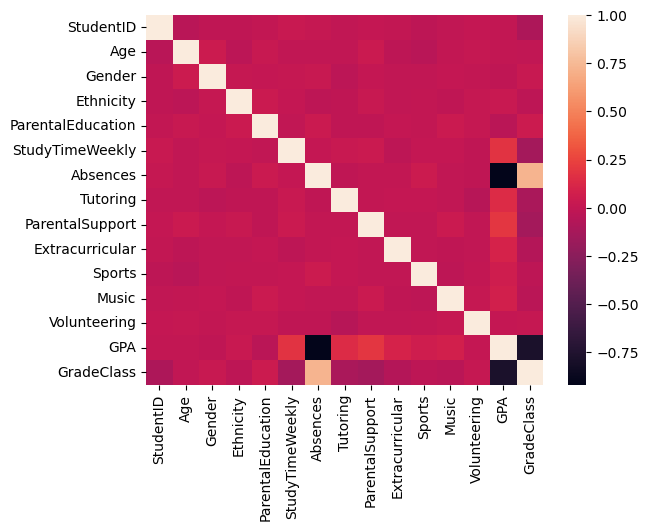

In [13]:
sns.heatmap(data.corr())

In [14]:
from sklearn.model_selection import train_test_split

In [15]:
# I'll split the data to a train and a test set (0.8/0.2).

In [16]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

In [17]:
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.model_selection import cross_val_score

In [18]:
# I'll build the model with ExtraTreesRegressor, since there are quite many predictors and it is easy to extract the most
# important ones with .feature_importances_. I will test and compare the model with all predictors and a subset of five most
# important ones.

In [19]:
reg = ExtraTreesRegressor(n_estimators=100).fit(X_train,y_train)

In [20]:
reg.score(X_train,y_train)

1.0

In [21]:
cross_val_score(reg,X_train,y_train,cv=5).mean()

0.9254835496582359

In [22]:
reg.score(X_test,y_test)

0.9349016780141344

In [23]:
# The scores are very good, so basically it is not necessary to drop the least important features. I'll do it nonetheless for
# the sake of comparison. Before that though, I'll tune the parameters of the model to select the best subset for prediction.

In [24]:
from sklearn.model_selection import GridSearchCV

In [25]:
tuned_parameters = [{'max_depth': range(3,10), 'min_samples_split': range(2,5),
                     'n_estimators': range(5,30)}]

In [26]:
tune_reg=GridSearchCV(reg, tuned_parameters, cv=3)

In [27]:
tune_reg.fit(X_train, y_train)

GridSearchCV(cv=3, estimator=ExtraTreesRegressor(),
             param_grid=[{'max_depth': range(3, 10),
                          'min_samples_split': range(2, 5),
                          'n_estimators': range(5, 30)}])

In [28]:
optimal_reg=tune_reg.best_estimator_

In [29]:
optimal_reg

ExtraTreesRegressor(max_depth=9, min_samples_split=4, n_estimators=25)

In [30]:
optimal_reg.score(X_train,y_train)

0.9685800683150836

In [31]:
cross_val_score(optimal_reg,X_train,y_train,cv=5).mean()

0.9220433821153508

In [32]:
optimal_reg.score(X_test,y_test)

0.9320947284094856

In [33]:
# The scores dropped a bit from the original model.

In [34]:
reg.feature_importances_

array([0.00741328, 0.00512392, 0.00620383, 0.00742243, 0.03705863,
       0.85091247, 0.018642  , 0.03514132, 0.01063554, 0.01126559,
       0.00636835, 0.00381263])

In [35]:
# To make it easier to grasp, the feature importances will be plotted.

[Text(0, 0, 'Age'),
 Text(1, 0, 'Gender'),
 Text(2, 0, 'Ethnicity'),
 Text(3, 0, 'ParentalEducation'),
 Text(4, 0, 'StudyTimeWeekly'),
 Text(5, 0, 'Absences'),
 Text(6, 0, 'Tutoring'),
 Text(7, 0, 'ParentalSupport'),
 Text(8, 0, 'Extracurricular'),
 Text(9, 0, 'Sports'),
 Text(10, 0, 'Music'),
 Text(11, 0, 'Volunteering')]

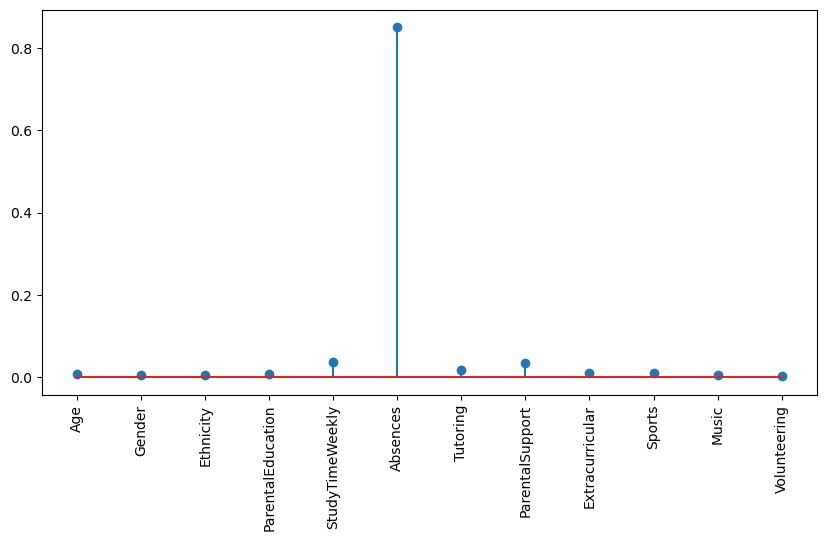

In [36]:
barplot=plt.figure(figsize=(10,5))
plt.stem(reg.feature_importances_)
ax=plt.gca()
ax.set_xticks(np.arange(12))
ax.set_xticklabels(X.columns,rotation=90)

In [37]:
# The most important feature (Absences) plotted against the GPA shows a very linear negative connection, as aforementioned.

<Axes: xlabel='Absences', ylabel='GPA'>

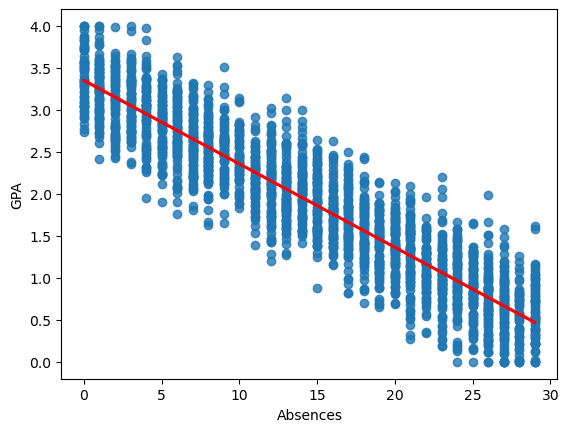

In [38]:
sns.regplot(y=y,x=X['Absences'],line_kws={"color": "red"})

In [39]:
# I'll select the five most important features and try to optimize the new ExtraTreesRegressor with them.

In [40]:
features=[]
selected=reg.feature_importances_.argsort()[-1:-6:-1]
for feature in selected:
    print(feature, X.columns[feature])
    features.append(X.columns[feature])
features

5 Absences
4 StudyTimeWeekly
7 ParentalSupport
6 Tutoring
9 Sports


['Absences', 'StudyTimeWeekly', 'ParentalSupport', 'Tutoring', 'Sports']

In [41]:
# Important to note, Absences was -0.92, ParentalSupport 0.19, StudyTimeWeekly 0.18 Tutoring 0.145, and Extracurricular 0.09 in 
# the correlation matrix. Therefore, according to the correlation matrix, all but Absence affect GPA positively.

In [42]:
X[features]

,Absences,StudyTimeWeekly,ParentalSupport,Tutoring,Sports
0,7,19.833723,2,1,0
1,0,15.408756,1,0,0
2,26,4.210570,2,0,0
3,14,10.028829,3,0,0
4,17,4.672495,3,1,0
...,...,...,...,...,...
2387,2,10.680555,4,0,0
2388,4,7.583217,4,1,1
2389,20,6.805500,2,0,0
2390,17,12.416653,2,0,1


In [43]:
Xopt_train, Xopt_test, yopt_train, yopt_test = train_test_split(X[features], y, test_size=0.2)

In [44]:
reg_opt = ExtraTreesRegressor(n_estimators=100, random_state=0).fit(Xopt_train,yopt_train)

In [45]:
reg_opt.score(Xopt_train,yopt_train)

1.0

In [46]:
cross_val_score(reg_opt,Xopt_train,yopt_train,cv=5).mean()

0.9141213305099842

In [47]:
reg_opt.score(Xopt_test,yopt_test)

0.9088209754902752

In [48]:
# The scores dropped a bit from the two earlier models. I'll plot the real and predicted GPA on both models to demonstrate their
# accuracy.

In [49]:
cv=cross_val_score(reg,X,y,cv=5).mean()

In [50]:
optimal_cv=cross_val_score(optimal_reg,X,y,cv=5).mean()

In [51]:
cv_opt=cross_val_score(reg_opt,X[features],y,cv=5).mean()

Text(0.5, 1.0, 'Original ExtraTreesRegressor, $R^2$=0.93')

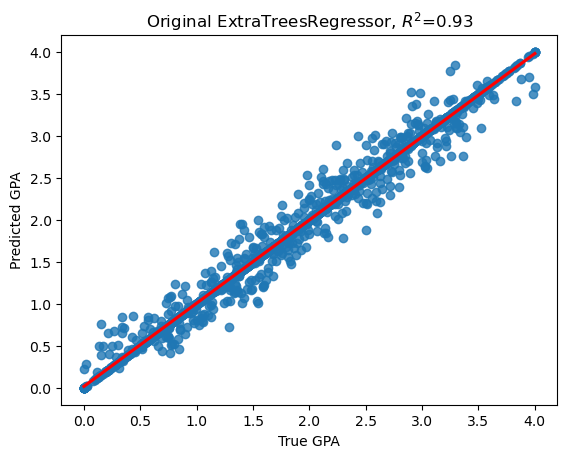

In [52]:
sns.regplot(x=y,y=reg.predict(X), line_kws={"color": "red"})
plt.xlabel('True GPA')
plt.ylabel('Predicted GPA')
plt.title('Original ExtraTreesRegressor, $R^2$=%3.2f' % cv)

Text(0.5, 1.0, 'Parameter tuned ExtraTreesRegressor, $R^2$=0.93')

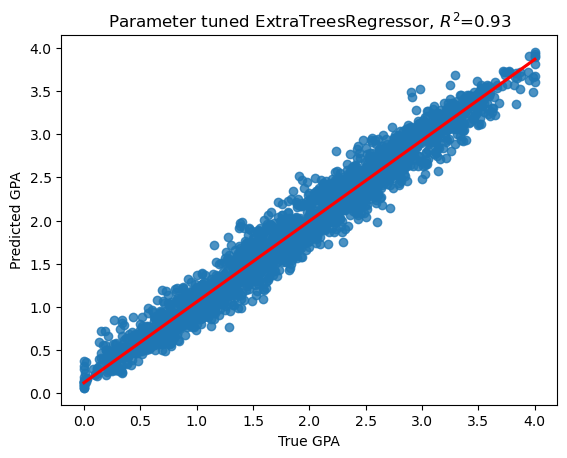

In [53]:
sns.regplot(x=y,y=optimal_reg.predict(X), line_kws={"color": "red"})
plt.xlabel('True GPA')
plt.ylabel('Predicted GPA')
plt.title('Parameter tuned ExtraTreesRegressor, $R^2$=%3.2f' % optimal_cv)

Text(0.5, 1.0, '5-feature ExtraTreesRegressor, $R^2$=0.91')

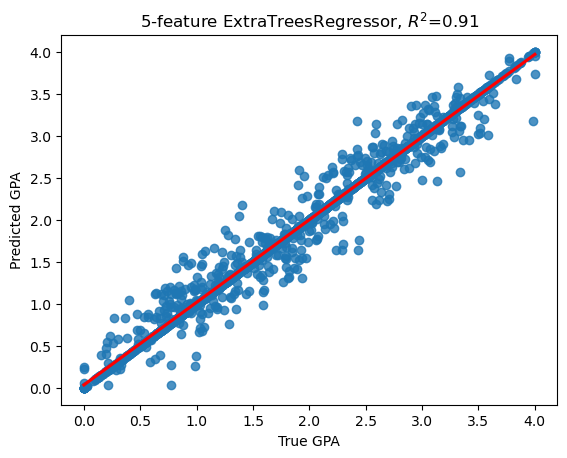

In [54]:
sns.regplot(x=y,y=reg_opt.predict(X[features]), line_kws={"color": "red"})
plt.xlabel('True GPA')
plt.ylabel('Predicted GPA')
plt.title('5-feature ExtraTreesRegressor, $R^2$=%3.2f' % cv_opt)

In [55]:
# The original ETR seems to be about 0.02 points better than the optimized one and about the same as the tuned parameters model. 
# This time, the full ETR-model and tuned parameters take the win.

In [56]:
# To have some fun and to compare the earlier models with Neural Networks, I'll create two ANN models, which regress the GPA 
# with all the features and with the five most important ones.

In [57]:
from sklearn.neural_network import MLPRegressor

In [58]:
nnreg = MLPRegressor(hidden_layer_sizes=(10,6), max_iter=500).fit(X_train,y_train)

In [59]:
nnreg.score(X_train,y_train)

0.9169371836871094

In [60]:
cross_val_score(nnreg,X_train,y_train,cv=5).mean()

0.9349487089929319

In [61]:
nnreg.score(X_test,y_test)

0.9284656742980905

In [62]:
nnreg_opt = MLPRegressor(hidden_layer_sizes=(10,6), max_iter=500).fit(Xopt_train,yopt_train)

In [63]:
nnreg_opt.score(Xopt_train,yopt_train)

0.9327125249186263

In [64]:
cross_val_score(nnreg_opt,Xopt_train,yopt_train,cv=5).mean()

0.9286728041233026

In [65]:
nnreg_opt.score(Xopt_test,yopt_test)

0.9370067684036197

In [66]:
nnreg_cv=cross_val_score(nnreg,X_train,y_train,cv=5).mean()

In [67]:
nnreg_opt_cv=cross_val_score(nnreg_opt,Xopt_train,yopt_train,cv=5).mean()

Text(0.5, 1.0, 'MLPRegressor, $R^2$=0.94')

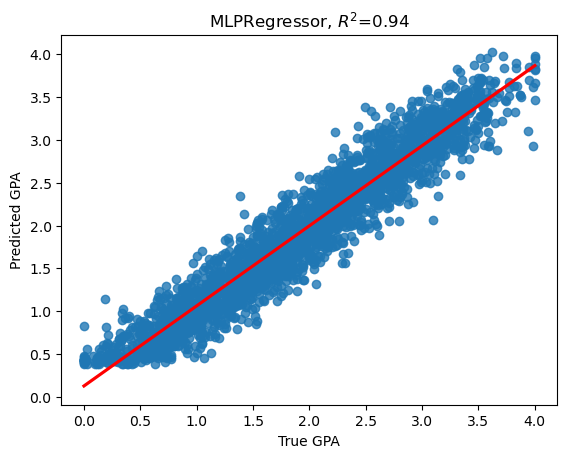

In [68]:
sns.regplot(x=y,y=nnreg.predict(X), line_kws={"color": "red"})
plt.xlabel('True GPA')
plt.ylabel('Predicted GPA')
plt.title('MLPRegressor, $R^2$=%3.2f' % nnreg_cv)

Text(0.5, 1.0, '5-feature MLPRegressor, $R^2$=0.93')

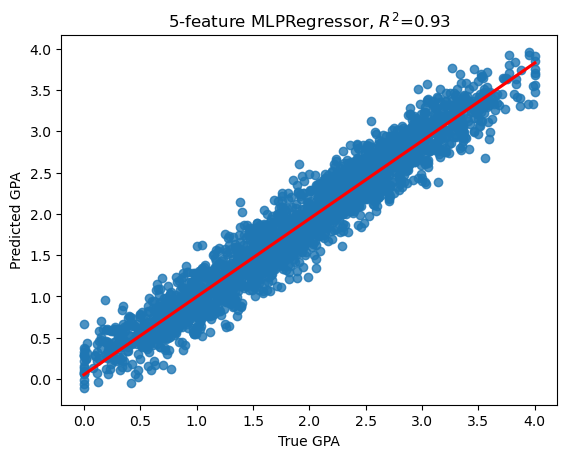

In [69]:
sns.regplot(x=y,y=nnreg_opt.predict(X[features]), line_kws={"color": "red"})
plt.xlabel('True GPA')
plt.ylabel('Predicted GPA')
plt.title('5-feature MLPRegressor, $R^2$=%3.2f' % nnreg_opt_cv)

In [70]:
# Thus far, the NN with all the features has had the best cv and test scores of every model. The every-feature ANN seems to be
# the best predictor, although the 5-feature ANN scored very well too.

In [75]:
import statsmodels.api as sm

In [76]:
X = sm.add_constant(X)

In [77]:
ordinary_reg = sm.OLS(y, X).fit()

In [78]:
print(ordinary_reg.summary())

                            OLS Regression Results                            
Dep. Variable:                    GPA   R-squared:                       0.954
Model:                            OLS   Adj. R-squared:                  0.954
Method:                 Least Squares   F-statistic:                     4118.
Date:                Tue, 19 Nov 2024   Prob (F-statistic):               0.00
Time:                        15:07:37   Log-Likelihood:                 502.85
No. Observations:                2392   AIC:                            -979.7
Df Residuals:                    2379   BIC:                            -904.6
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                 2.5974      0.06

In [71]:
# To conclude the model building, a linear regressor worked very well this time to predict GPA. Absences was the most important
# predictor in the data, but it is possible that in other data sets it would not achieve such significance. ANNs scored the best
#, but they require also more computing power, i. e. give or take.